# Data Quality Assessment

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("data.csv", encoding="cp1252")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


## Missing values
A missing value occurs when a field has no recorded value. For example, a retail transaction might have a missing CustomerID or Description.
### Count missing values
Use isnull() and sum() to count missing values in each column.

In [2]:
# Count missing values in each column
missing_counts = df.isnull().sum()

print("Missing values by column:")
print(missing_counts)

# Total missing cells
print("\nTotal missing values:", df.isnull().sum().sum())

Missing values by column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Total missing values: 136534


### Percentage of missing values
A column with many missing values may need special treatment before machine learning.

In [3]:
missing_percentage = (
    df.isnull().sum() / len(df) * 100
)

missing_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": missing_percentage.round(2)
})

missing_report = missing_report.sort_values(
    "Missing Percentage",
    ascending=False
)

print(missing_report)


             Missing Count  Missing Percentage
CustomerID          135080               24.93
Description           1454                0.27
StockCode                0                0.00
InvoiceNo                0                0.00
Quantity                 0                0.00
InvoiceDate              0                0.00
UnitPrice                0                0.00
Country                  0                0.00


### Find columns containing missing values

In [4]:
columns_with_missing = missing_report[
    missing_report["Missing Count"] > 0
]

print(columns_with_missing)

             Missing Count  Missing Percentage
CustomerID          135080               24.93
Description           1454                0.27


### Visualize missing values

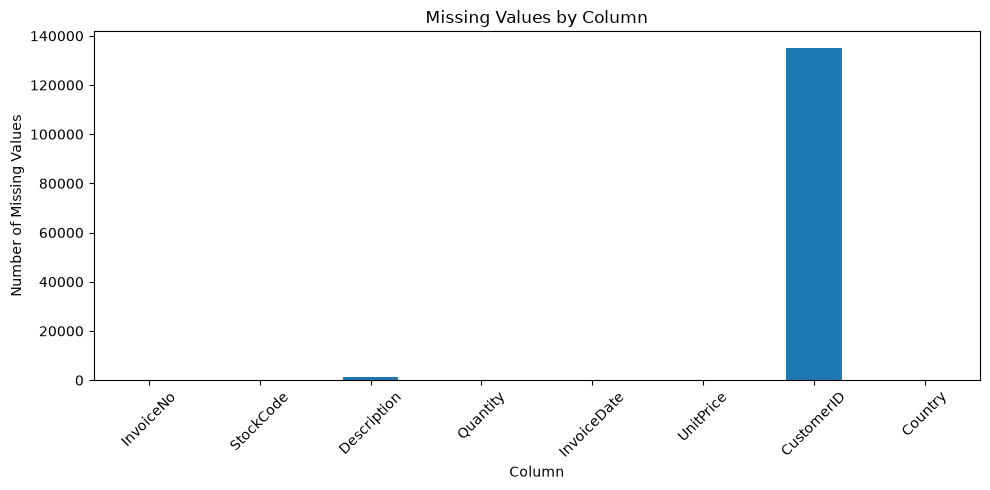

In [5]:
# Visualize missing values by column
df.isnull().sum().plot(
    kind="bar",
    figsize=(10, 5),
    title="Missing Values by Column"
)

plt.ylabel("Number of Missing Values")
plt.xlabel("Column")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Investigate missing-value patterns
Missing-value patterns help us understand whether missing fields occur together in the same records.

In [6]:
# Display missing-value patterns for the first 20 rows
print(df.isnull().head(20).astype(int))

# Count common patterns across columns
patterns = (
    df.isnull()
    .value_counts()
    .reset_index(name="Number of Rows")
)

print(patterns.head(10))

    InvoiceNo  StockCode  Description  Quantity  InvoiceDate  UnitPrice  \
0           0          0            0         0            0          0   
1           0          0            0         0            0          0   
2           0          0            0         0            0          0   
3           0          0            0         0            0          0   
4           0          0            0         0            0          0   
5           0          0            0         0            0          0   
6           0          0            0         0            0          0   
7           0          0            0         0            0          0   
8           0          0            0         0            0          0   
9           0          0            0         0            0          0   
10          0          0            0         0            0          0   
11          0          0            0         0            0          0   
12          0          0 

## Duplicate records
A duplicate record is a row that repeats another row or potentially represents the same business event.
Duplicates can distort sales totals, statistical summaries, and machine learning results.

In [8]:
# Check whether each row is duplicated
duplicate_mask = df.duplicated()

print("Total duplicate rows:", duplicate_mask.sum())

# Display duplicate records
duplicate_rows = df[df.duplicated(keep=False)]

duplicate_rows.head(10)

Total duplicate rows: 5268


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,12/1/2010 11:49,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,12/1/2010 11:49,2.95,17920.0,United Kingdom


## Count duplicates

In [9]:
total_duplicates = df.duplicated().sum()
unique_rows = len(df.drop_duplicates())

print("Total rows:", len(df))
print("Duplicate rows after first occurrences:", total_duplicates)
print("Rows remaining after removing exact duplicates:", unique_rows)

Total rows: 541909
Duplicate rows after first occurrences: 5268
Rows remaining after removing exact duplicates: 536641


## Identify potential duplicate records
Two rows can represent the same business event even if they are not identical in every column.
### Example
Investigate repeated combinations of invoice number, product code, and price.

In [10]:
# Check repeated invoice-product-price combinations
key_columns = ["InvoiceNo", "StockCode", "UnitPrice"]

potential_duplicates = df[
    df.duplicated(subset=key_columns, keep=False)
].sort_values(key_columns)

print("Potential repeated combinations:", len(potential_duplicates))

potential_duplicates.head(10)

Potential repeated combinations: 19278


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
113,536381,71270,PHOTO CLIP LINE,1,12/1/2010 9:41,1.25,15311.0,United Kingdom
125,536381,71270,PHOTO CLIP LINE,3,12/1/2010 9:41,1.25,15311.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom


## Check repeated invoice numbers

In [11]:
invoice_counts = df["InvoiceNo"].value_counts()

print("Most frequent invoice numbers:")
print(invoice_counts.head(10))

Most frequent invoice numbers:
InvoiceNo
573585    1114
581219     749
581492     731
580729     721
558475     705
579777     687
581217     676
537434     675
580730     662
538071     652
Name: count, dtype: int64


## Invalid values
Invalid values are values that violate expected business rules, contain impossible measurements, or cannot be interpreted correctly.
For the retail dataset, we will check negative quantities, negative prices, impossible dates, unexpected categories, and incorrect data types.
### Negative quantities
Negative quantities may indicate returns or corrections, so they are not automatically errors.

In [12]:
negative_quantity = df[df["Quantity"] < 0]

print("Rows with negative quantities:", len(negative_quantity))

negative_quantity[
    ["InvoiceNo", "StockCode", "Quantity", "InvoiceDate"]
].head(10)

Rows with negative quantities: 10624


,InvoiceNo,StockCode,Quantity,InvoiceDate
141,C536379,D,-1,12/1/2010 9:41
154,C536383,35004C,-1,12/1/2010 9:49
235,C536391,22556,-12,12/1/2010 10:24
236,C536391,21984,-24,12/1/2010 10:24
237,C536391,21983,-24,12/1/2010 10:24
238,C536391,21980,-24,12/1/2010 10:24
239,C536391,21484,-12,12/1/2010 10:24
240,C536391,22557,-12,12/1/2010 10:24
241,C536391,22553,-24,12/1/2010 10:24
939,C536506,22960,-6,12/1/2010 12:38


### Negative quantities
Negative quantities may indicate returns or corrections, so they are not automatically errors.


In [14]:
negative_quantity = df[df["Quantity"] < 0]

print("Rows with negative quantities:", len(negative_quantity))

negative_quantity[
    ["InvoiceNo", "StockCode", "Quantity", "InvoiceDate"]
].head(10)

Rows with negative quantities: 10624


,InvoiceNo,StockCode,Quantity,InvoiceDate
141,C536379,D,-1,12/1/2010 9:41
154,C536383,35004C,-1,12/1/2010 9:49
235,C536391,22556,-12,12/1/2010 10:24
236,C536391,21984,-24,12/1/2010 10:24
237,C536391,21983,-24,12/1/2010 10:24
238,C536391,21980,-24,12/1/2010 10:24
239,C536391,21484,-12,12/1/2010 10:24
240,C536391,22557,-12,12/1/2010 10:24
241,C536391,22553,-24,12/1/2010 10:24
939,C536506,22960,-6,12/1/2010 12:38


### Negative or zero unit prices
Negative prices may require investigation. A zero price may represent a free item, promotion, or an incomplete record.

In [15]:
negative_price = df[df["UnitPrice"] < 0]
zero_price = df[df["UnitPrice"] == 0]

print("Negative unit prices:", len(negative_price))
print("Zero unit prices:", len(zero_price))

negative_price[
    ["InvoiceNo", "StockCode", "Quantity", "UnitPrice"]
].head(10)

Negative unit prices: 2
Zero unit prices: 2515


,InvoiceNo,StockCode,Quantity,UnitPrice
299983,A563186,B,1,-11062.06
299984,A563187,B,1,-11062.06


### Impossible or invalid dates
Convert the invoice date to a datetime format. Invalid dates become NaT (Not a Time).

In [16]:
# Keep the original values for comparison
original_dates = df["InvoiceDate"].copy()

parsed_dates = pd.to_datetime(
    original_dates,
    errors="coerce"
)

invalid_dates = original_dates.notna() & parsed_dates.isna()

print("Invalid date values:", invalid_dates.sum())

print("Invalid date examples:")
print(original_dates[invalid_dates].head(10))

Invalid date values: 0
Invalid date examples:
Series([], Name: InvoiceDate, dtype: str)


### Incorrect categories
Categorical columns can contain inconsistent labels, such as "United Kingdom" and "United Kingdom ".

In [17]:
print("Country categories:")
print(df["Country"].value_counts(dropna=False).head(20))

# Find values with leading or trailing whitespace
country_text = df["Country"].astype("string")

whitespace_mask = (
    country_text.notna()
    & country_text.ne(country_text.str.strip()).fillna(False)
)

print(
    "Country values with extra surrounding spaces:",
    whitespace_mask.sum()
)

print(df.loc[whitespace_mask, ["Country"]].head(10))

Country categories:
Country
United Kingdom     495478
Germany              9495
France               8557
EIRE                 8196
Spain                2533
Netherlands          2371
Belgium              2069
Switzerland          2002
Portugal             1519
Australia            1259
Norway               1086
Italy                 803
Channel Islands       758
Finland               695
Cyprus                622
Sweden                462
Unspecified           446
Austria               401
Denmark               389
Japan                 358
Name: count, dtype: int64
Country values with extra surrounding spaces: 0
Empty DataFrame
Columns: [Country]
Index: []


### Unexpected values
Check whether numerical values fall outside reasonable business limits. The correct limits depend on the use case.

In [19]:
# Basic range checks
print("Quantity minimum:", df["Quantity"].min())
print("Quantity maximum:", df["Quantity"].max())

print("UnitPrice minimum:", df["UnitPrice"].min())
print("UnitPrice maximum:", df["UnitPrice"].max())

# Flag unusually large quantities for investigation
quantity_threshold = df["Quantity"].quantile(0.99)

unusually_large_quantity = df[
    df["Quantity"] > quantity_threshold
]

print("99th percentile quantity:", quantity_threshold)
print(
    "Rows above 99th percentile:",
    len(unusually_large_quantity)
)

Quantity minimum: -80995
Quantity maximum: 80995
UnitPrice minimum: -11062.06
UnitPrice maximum: 38970.0
99th percentile quantity: 100.0
Rows above 99th percentile: 4950


## Empty strings and null-like values
Not every missing value is stored as a normal Pandas NaN. Some files use empty strings or text such as "NULL", "N/A", or "unknown".

In [20]:
object_columns = df.select_dtypes(
    include=["object", "string"]
).columns

for column in object_columns:
    empty_count = (
        df[column]
        .astype("string")
        .str.strip()
        .eq("")
        .fillna(False)
        .sum()
    )

    print(f"{column}: {empty_count} empty strings")

InvoiceNo: 0 empty strings
StockCode: 0 empty strings
Description: 0 empty strings
InvoiceDate: 0 empty strings
Country: 0 empty strings


### Detect null-like text

In [21]:
null_like_values = [
    "NULL", "N/A", "NA", "NONE", "UNKNOWN"
]

for column in object_columns:
    text_values = df[column].astype("string").str.strip()

    mask = text_values.str.upper().isin(null_like_values)

    print(f"{column}: {mask.sum()} null-like text values")

InvoiceNo: 0 null-like text values
StockCode: 0 null-like text values
Description: 0 null-like text values
InvoiceDate: 0 null-like text values
Country: 0 null-like text values
